In [1]:
!apt-get -qq update
!apt-get -qq install -y openjdk-17-jdk-headless
!pip -q install pyspark==3.5.5 pandas matplotlib

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-17-jre-headless:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.21.0.3+1-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jre-headless:amd64 (17.0.21.0.3+1-1~24.04.1) ...
Selecting previously unselected package openjdk-17-jdk-headless:amd64.
Preparing to unpack .../openjdk-17-jdk-headless_17.0.21.0.3+1-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jdk-headless:amd64 (17.0.21.0.3+1-1~24.04.1) ...
Setting up openjdk-17-jre-headless:amd64 (17.0.21.0.3+1-1~24.04.1) ...
Processing triggers for ca-certificates-java (20240118) ...
[0.011s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't

In [2]:
import os, glob, json, time, shutil
from pathlib import Path
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

import pyspark
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark import StorageLevel

print("PySpark:", pyspark.__version__)
print(os.popen("java -version 2>&1").read().splitlines()[0])

PySpark: 3.5.5
openjdk version "17.0.21.0.3" 2026-10-24


In [3]:
from google.colab import files
import os, re

uploaded_collision = files.upload()
if len(uploaded_collision) != 1:
    raise ValueError("Select exactly ONE collision CSV.")
collision_filename = next(iter(uploaded_collision))
if not collision_filename.lower().endswith(".csv") or not re.search(r"(^|[-_ ])collision([-_ .]|$)", collision_filename, re.I):
    raise ValueError(f"Wrong file: {collision_filename}. Select the official collision CSV.")
COLLISIONS_PATH = os.path.join("/content", collision_filename)
print("Collision file accepted:", collision_filename)
print("Size MB:", round(os.path.getsize(COLLISIONS_PATH)/1024**2, 2))

Saving dft-road-casualty-statistics-collision-last-5-years.csv to dft-road-casualty-statistics-collision-last-5-years.csv
Collision file accepted: dft-road-casualty-statistics-collision-last-5-years.csv
Size MB: 93.14


In [4]:
uploaded_vehicle = files.upload()
if len(uploaded_vehicle) != 1:
    raise ValueError("Select exactly ONE vehicle CSV.")
vehicle_filename = next(iter(uploaded_vehicle))
if not vehicle_filename.lower().endswith(".csv") or not re.search(r"(^|[-_ ])vehicle([-_ .]|$)", vehicle_filename, re.I):
    raise ValueError(f"Wrong file: {vehicle_filename}. Select the official vehicle CSV.")
VEHICLES_PATH = os.path.join("/content", vehicle_filename)
if os.path.abspath(VEHICLES_PATH) == os.path.abspath(COLLISIONS_PATH):
    raise AssertionError("Vehicle and collision files must be different.")
print("Vehicle file accepted:", vehicle_filename)
print("Size MB:", round(os.path.getsize(VEHICLES_PATH)/1024**2, 2))

Saving dft-road-casualty-statistics-vehicle-last-5-years.csv to dft-road-casualty-statistics-vehicle-last-5-years.csv
Vehicle file accepted: dft-road-casualty-statistics-vehicle-last-5-years.csv
Size MB: 98.94


In [5]:
uploaded_casualty = files.upload()
if len(uploaded_casualty) != 1:
    raise ValueError("Select exactly ONE casualty CSV.")
casualty_filename = next(iter(uploaded_casualty))
if not casualty_filename.lower().endswith(".csv") or not re.search(r"(^|[-_ ])casualty([-_ .]|$)", casualty_filename, re.I):
    raise ValueError(f"Wrong file: {casualty_filename}. Select the official casualty CSV.")
CASUALTIES_PATH = os.path.join("/content", casualty_filename)
source_paths = [os.path.abspath(COLLISIONS_PATH), os.path.abspath(VEHICLES_PATH), os.path.abspath(CASUALTIES_PATH)]
if len(set(source_paths)) != 3:
    raise AssertionError("All three source files must be different.")
print("All three source files validated:")
print("Collision:", os.path.basename(COLLISIONS_PATH))
print("Vehicle:  ", os.path.basename(VEHICLES_PATH))
print("Casualty: ", os.path.basename(CASUALTIES_PATH))

Saving dft-road-casualty-statistics-casualty-last-5-years.csv to dft-road-casualty-statistics-casualty-last-5-years.csv
All three source files validated:
Collision: dft-road-casualty-statistics-collision-last-5-years.csv
Vehicle:   dft-road-casualty-statistics-vehicle-last-5-years.csv
Casualty:  dft-road-casualty-statistics-casualty-last-5-years.csv


In [6]:
spark = (
    SparkSession.builder
    .appName("B142_UK_Road_Safety_Integration")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
start_time = time.time()

def read_csv(path):
    return (spark.read.option("header", True)
            .option("inferSchema", False)
            .option("mode", "PERMISSIVE")
            .option("encoding", "UTF-8")
            .csv(path))

collisions_raw = read_csv(COLLISIONS_PATH).persist(StorageLevel.MEMORY_AND_DISK)
vehicles_raw = read_csv(VEHICLES_PATH).persist(StorageLevel.MEMORY_AND_DISK)
casualties_raw = read_csv(CASUALTIES_PATH).persist(StorageLevel.MEMORY_AND_DISK)

print("Raw counts:", collisions_raw.count(), vehicles_raw.count(), casualties_raw.count())
print("COLLISIONS SCHEMA"); collisions_raw.printSchema()
print("VEHICLES SCHEMA"); vehicles_raw.printSchema()
print("CASUALTIES SCHEMA"); casualties_raw.printSchema()

Raw counts: 513801 937265 652821
COLLISIONS SCHEMA
root
 |-- collision_index: string (nullable = true)
 |-- collision_year: string (nullable = true)
 |-- collision_ref_no: string (nullable = true)
 |-- location_easting_osgr: string (nullable = true)
 |-- location_northing_osgr: string (nullable = true)
 |-- longitude: string (nullable = true)
 |-- latitude: string (nullable = true)
 |-- police_force: string (nullable = true)
 |-- collision_severity: string (nullable = true)
 |-- number_of_vehicles: string (nullable = true)
 |-- number_of_casualties: string (nullable = true)
 |-- date: string (nullable = true)
 |-- day_of_week: string (nullable = true)
 |-- time: string (nullable = true)
 |-- local_authority_district: string (nullable = true)
 |-- local_authority_ons_district: string (nullable = true)
 |-- local_authority_highway: string (nullable = true)
 |-- local_authority_highway_current: string (nullable = true)
 |-- first_road_class: string (nullable = true)
 |-- first_road_number

In [7]:
import re

def standardise_name(name):
    name = re.sub(r"([a-z0-9])([A-Z])", r"\1_\2", name)
    name = re.sub(r"[^A-Za-z0-9]+", "_", name)
    return name.strip("_").lower()

def standardise_columns(df):
    # Avoid duplicate names after normalisation.
    seen = {}
    renamed = []
    for old in df.columns:
        base = standardise_name(old)
        count = seen.get(base, 0)
        seen[base] = count + 1
        renamed.append(base if count == 0 else f"{base}_{count+1}")
    for old, new in zip(df.columns, renamed):
        if old != new:
            df = df.withColumnRenamed(old, new)
    return df

def clean_df(df):
    df = standardise_columns(df)
    exprs = []
    for field in df.schema.fields:
        c = F.col(field.name)
        if isinstance(field.dataType, T.StringType):
            exprs.append(
                F.when(F.trim(c) == "", F.lit(None)).otherwise(F.trim(c)).alias(field.name)
            )
        else:
            exprs.append(c)
    return df.select(*exprs).dropDuplicates()

def missing_counts(df):
    return df.select([
        F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c)
        for c in df.columns
    ])

collisions_clean = clean_df(collisions_raw).persist(StorageLevel.MEMORY_AND_DISK)
vehicles_clean = clean_df(vehicles_raw).persist(StorageLevel.MEMORY_AND_DISK)
casualties_clean = clean_df(casualties_raw).persist(StorageLevel.MEMORY_AND_DISK)

for label, before, after in [
    ("COLLISIONS", collisions_raw, collisions_clean),
    ("VEHICLES", vehicles_raw, vehicles_clean),
    ("CASUALTIES", casualties_raw, casualties_clean)
]:
    print("\n", label)
    print("Rows before:", before.count())
    print("Exact duplicates removed:", before.count() - after.count())
    print("Rows after:", after.count())
    print("Missing-value profile:")
    missing_counts(after).show(truncate=False)


 COLLISIONS
Rows before: 513801
Exact duplicates removed: 0
Rows after: 513801
Missing-value profile:
+---------------+--------------+----------------+---------------------+----------------------+---------+--------+------------+------------------+------------------+--------------------+----+-----------+----+------------------------+----------------------------+-----------------------+-------------------------------+----------------+-----------------+---------+-----------+------------------------+---------------+----------------+-----------------+------------------+------------------------------------------+------------------------------------------------+-------------------+----------------+------------------+-----------------------+--------------------------+----------------------------+-------------------+-------------------+-------------------------------------------+---------------+-------------------------+---------------------------+----------------------+-----------------------

In [8]:
KEY_CANDIDATES = [
    "accident_index", "Accident_Index", "collision_index",
    "collision_id", "accident_id"
]

def find_col(df, candidates):
    lookup = {c.lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

collision_key = find_col(collisions_clean, KEY_CANDIDATES)
vehicle_key = find_col(vehicles_clean, KEY_CANDIDATES)
casualty_key = find_col(casualties_clean, KEY_CANDIDATES)

print("Detected join keys:", collision_key, vehicle_key, casualty_key)
if not all([collision_key, vehicle_key, casualty_key]):
    raise ValueError(
        "Collision join key not found in all three tables. Inspect schemas and "
        "add the exact field name to KEY_CANDIDATES."
    )

# Keep original source key, but create one common standardised key.
for frame_name, key in [
    ("collisions_clean", collision_key),
    ("vehicles_clean", vehicle_key),
    ("casualties_clean", casualty_key)
]:
    frame = globals()[frame_name]
    frame = frame.filter(F.col(key).isNotNull())
    frame = frame.withColumn("_collision_key", F.trim(F.col(key).cast("string")))
    globals()[frame_name] = frame

# Validate collision table key uniqueness.
duplicate_collision_key_rows = (
    collisions_clean.groupBy("_collision_key").count()
    .filter(F.col("count") > 1)
)
duplicate_collision_keys = duplicate_collision_key_rows.count()
print("Collision keys appearing more than once:", duplicate_collision_keys)

# The collision-level output must have one record per key.
collision_base = collisions_clean.dropDuplicates(["_collision_key"])
collision_keys = collision_base.select("_collision_key").distinct()
unmatched_vehicle_rows = vehicles_clean.join(collision_keys, "_collision_key", "left_anti").count()
unmatched_casualty_rows = casualties_clean.join(collision_keys, "_collision_key", "left_anti").count()

print("Vehicle rows without a matching collision:", unmatched_vehicle_rows)
print("Casualty rows without a matching collision:", unmatched_casualty_rows)

numeric_candidates = [
    "accident_year", "number_of_vehicles", "number_of_casualties",
    "vehicle_type", "casualty_severity", "accident_severity",
    "speed_limit", "number_of_casualties"
]
for frame_name in ["collisions_clean", "vehicles_clean", "casualties_clean"]:
    frame = globals()[frame_name]
    for field in numeric_candidates:
        if field in frame.columns:
            frame = frame.withColumn(field, F.expr(f"try_cast(`{field}` as double)"))
    globals()[frame_name] = frame

print("Preprocessing complete. Nulls in non-key fields are retained and documented.")

Detected join keys: collision_index collision_index collision_index
Collision keys appearing more than once: 0
Vehicle rows without a matching collision: 0
Casualty rows without a matching collision: 0
Preprocessing complete. Nulls in non-key fields are retained and documented.


In [9]:
vehicle_counts = vehicles_clean.groupBy("_collision_key").agg(
    F.count(F.lit(1)).alias("vehicle_count")
)
casualty_counts = casualties_clean.groupBy("_collision_key").agg(
    F.count(F.lit(1)).alias("casualty_count")
)

integrated = (
    collision_base
    .join(vehicle_counts, "_collision_key", "left")
    .join(casualty_counts, "_collision_key", "left")
    .fillna({"vehicle_count": 0, "casualty_count": 0})
)

collision_rows = collision_base.count()
integrated_rows = integrated.count()
print("Collision base rows:", collision_rows)
print("Integrated rows:", integrated_rows)
print("Integration row preservation:", integrated_rows == collision_rows)
if integrated_rows != collision_rows:
    raise AssertionError("Integrated row count changed unexpectedly.")
integrated.printSchema()

Collision base rows: 513801
Integrated rows: 513801
Integration row preservation: True
root
 |-- _collision_key: string (nullable = true)
 |-- collision_index: string (nullable = true)
 |-- collision_year: string (nullable = true)
 |-- collision_ref_no: string (nullable = true)
 |-- location_easting_osgr: string (nullable = true)
 |-- location_northing_osgr: string (nullable = true)
 |-- longitude: string (nullable = true)
 |-- latitude: string (nullable = true)
 |-- police_force: string (nullable = true)
 |-- collision_severity: string (nullable = true)
 |-- number_of_vehicles: string (nullable = true)
 |-- number_of_casualties: string (nullable = true)
 |-- date: string (nullable = true)
 |-- day_of_week: string (nullable = true)
 |-- time: string (nullable = true)
 |-- local_authority_district: string (nullable = true)
 |-- local_authority_ons_district: string (nullable = true)
 |-- local_authority_highway: string (nullable = true)
 |-- local_authority_highway_current: string (nulla

In [11]:
import os

# Create main output directory
OUTPUT_DIR = "/content/UK_Road_Safety_Spark_Outputs"

# Create all required folders
folders = [
    "parquet",
    "sql_results",
    "charts",
    "json_interchange"
]

for folder in folders:
    os.makedirs(
        os.path.join(OUTPUT_DIR, folder),
        exist_ok=True
    )

print("Output directories created successfully!")
print("Output location:", OUTPUT_DIR)

Output directories created successfully!
Output location: /content/UK_Road_Safety_Spark_Outputs


In [12]:
JSON_DIR = os.path.join(OUTPUT_DIR, "json_interchange", "integrated_sample")
json_sample = integrated.limit(5000)
json_sample.write.mode("overwrite").json(JSON_DIR)

integrated_from_json = spark.read.json(JSON_DIR)
json_sample_rows = json_sample.count()
json_round_trip_rows = integrated_from_json.count()

print("JSON sample rows written:", json_sample_rows)
print("JSON sample rows read back:", json_round_trip_rows)
integrated_from_json.printSchema()

if json_sample_rows != json_round_trip_rows:
    raise AssertionError("JSON round-trip row count does not match.")
print("JSON interoperability check: PASSED")

JSON sample rows written: 5000
JSON sample rows read back: 5000
root
 |-- _collision_key: string (nullable = true)
 |-- carriageway_hazards: string (nullable = true)
 |-- carriageway_hazards_historic: string (nullable = true)
 |-- casualty_count: long (nullable = true)
 |-- collision_adjusted_severity_serious: string (nullable = true)
 |-- collision_adjusted_severity_slight: string (nullable = true)
 |-- collision_index: string (nullable = true)
 |-- collision_injury_based: string (nullable = true)
 |-- collision_ref_no: string (nullable = true)
 |-- collision_severity: string (nullable = true)
 |-- collision_year: string (nullable = true)
 |-- date: string (nullable = true)
 |-- day_of_week: string (nullable = true)
 |-- did_police_officer_attend_scene_of_accident: string (nullable = true)
 |-- enhanced_severity_collision: string (nullable = true)
 |-- first_road_class: string (nullable = true)
 |-- first_road_number: string (nullable = true)
 |-- junction_control: string (nullable = 

In [13]:
integrated.createOrReplaceTempView("road_collisions")
vehicles_clean.createOrReplaceTempView("road_vehicles")
casualties_clean.createOrReplaceTempView("road_casualties")

def pick(columns, candidates):
    lookup = {c.lower(): c for c in columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

severity_col = pick(integrated.columns, ["accident_severity", "collision_severity", "severity"])
year_col = pick(integrated.columns, ["accident_year", "year"])
date_col = pick(integrated.columns, ["date", "collision_date", "accident_date"])
road_col = pick(integrated.columns, ["road_type", "1st_road_class", "road_class"])
light_col = pick(integrated.columns, ["light_conditions", "light_condition"])
weather_col = pick(integrated.columns, ["weather_conditions", "weather_condition"])
urban_col = pick(integrated.columns, ["urban_or_rural_area", "urban_rural"])

if year_col is None and date_col is not None:
    integrated = integrated.withColumn(
        "_analysis_year", F.year(F.to_date(F.col(date_col), "d/M/yyyy"))
    )
    integrated.createOrReplaceTempView("road_collisions")
    year_col = "_analysis_year"

SQL_DIR = os.path.join(OUTPUT_DIR, "sql_results")
os.makedirs(SQL_DIR, exist_ok=True)

def run_sql(label, query, filename):
    print("\n" + label)
    result = spark.sql(query)
    result.show(30, truncate=False)
    (result.coalesce(1).write.mode("overwrite")
     .option("header", True).csv(os.path.join(SQL_DIR, filename)))
    return result

overall_sql = run_sql(
    "Overall collision and associated record totals",
    "SELECT COUNT(*) AS collision_records, "
    "SUM(COALESCE(vehicle_count,0)) AS vehicle_records, "
    "SUM(COALESCE(casualty_count,0)) AS casualty_records FROM road_collisions",
    "overall_summary"
)

if severity_col:
    severity_sql = run_sql(
        "Collision count by severity",
        f"SELECT `{severity_col}` AS severity, COUNT(*) AS collision_count "
        f"FROM road_collisions GROUP BY `{severity_col}` ORDER BY collision_count DESC",
        "by_severity"
    )

if year_col:
    year_sql = run_sql(
        "Collision count by year",
        f"SELECT `{year_col}` AS year, COUNT(*) AS collision_count "
        f"FROM road_collisions WHERE `{year_col}` IS NOT NULL "
        f"GROUP BY `{year_col}` ORDER BY year",
        "by_year"
    )

if road_col:
    road_sql = run_sql(
        "Collision count by road type/class",
        f"SELECT `{road_col}` AS road_category, COUNT(*) AS collision_count "
        f"FROM road_collisions GROUP BY `{road_col}` ORDER BY collision_count DESC",
        "by_road_category"
    )

if light_col:
    light_sql = run_sql(
        "Collision count by light condition",
        f"SELECT `{light_col}` AS light_condition, COUNT(*) AS collision_count "
        f"FROM road_collisions GROUP BY `{light_col}` ORDER BY collision_count DESC",
        "by_light_condition"
    )

if weather_col:
    weather_sql = run_sql(
        "Collision count by weather condition",
        f"SELECT `{weather_col}` AS weather_condition, COUNT(*) AS collision_count "
        f"FROM road_collisions GROUP BY `{weather_col}` ORDER BY collision_count DESC",
        "by_weather_condition"
    )

print("Detected fields:", {
    "severity": severity_col, "year": year_col, "road": road_col,
    "light": light_col, "weather": weather_col, "urban_rural": urban_col
})


# Detailed child-table analytics: these operate on the original child tables,
# not on the collision-level aggregate.
vehicle_type_col = pick(vehicles_clean.columns, ["vehicle_type"])
if vehicle_type_col:
    vehicle_type_sql = run_sql(
        "Vehicle records by vehicle type",
        f"SELECT `{vehicle_type_col}` AS vehicle_type, COUNT(*) AS record_count "
        f"FROM road_vehicles WHERE `{vehicle_type_col}` IS NOT NULL "
        f"GROUP BY `{vehicle_type_col}` ORDER BY record_count DESC",
        "vehicle_type"
    )

casualty_severity_col = pick(casualties_clean.columns, ["casualty_severity"])
if casualty_severity_col:
    casualty_severity_sql = run_sql(
        "Casualty records by casualty severity",
        f"SELECT `{casualty_severity_col}` AS casualty_severity, COUNT(*) AS record_count "
        f"FROM road_casualties WHERE `{casualty_severity_col}` IS NOT NULL "
        f"GROUP BY `{casualty_severity_col}` ORDER BY record_count DESC",
        "casualty_severity"
    )



Overall collision and associated record totals
+-----------------+---------------+----------------+
|collision_records|vehicle_records|casualty_records|
+-----------------+---------------+----------------+
|513801           |937265         |652821          |
+-----------------+---------------+----------------+


Collision count by severity
+--------+---------------+
|severity|collision_count|
+--------+---------------+
|3       |389435         |
|2       |116813         |
|1       |7553           |
+--------+---------------+


Collision count by year
+----+---------------+
|year|collision_count|
+----+---------------+
|2021|101087         |
|2022|106004         |
|2023|104258         |
|2024|100927         |
|2025|101525         |
+----+---------------+


Collision count by road type/class
+-------------+---------------+
|road_category|collision_count|
+-------------+---------------+
|6            |373065         |
|3            |76119          |
|1            |31178          |
|9    

In [14]:
# Filter to records with a valid collision key and at least one associated vehicle.
filtered_sql = run_sql(
    "Filtered collision records with one or more associated vehicles",
    "SELECT COUNT(*) AS filtered_collision_count, "
    "AVG(vehicle_count) AS mean_vehicles_per_collision, "
    "AVG(casualty_count) AS mean_casualties_per_collision, "
    "MAX(vehicle_count) AS maximum_vehicles_in_a_collision, "
    "MAX(casualty_count) AS maximum_casualties_in_a_collision "
    "FROM road_collisions WHERE vehicle_count >= 1",
    "filtered_statistical_summary"
)

descriptive_stats = integrated.select(
    F.count("*").alias("collision_count"),
    F.avg("vehicle_count").alias("mean_vehicles_per_collision"),
    F.stddev("vehicle_count").alias("sd_vehicles_per_collision"),
    F.avg("casualty_count").alias("mean_casualties_per_collision"),
    F.stddev("casualty_count").alias("sd_casualties_per_collision"),
    F.min("vehicle_count").alias("min_vehicles"),
    F.max("vehicle_count").alias("max_vehicles"),
    F.min("casualty_count").alias("min_casualties"),
    F.max("casualty_count").alias("max_casualties")
)
print("Descriptive statistics:")
descriptive_stats.show(truncate=False)
descriptive_stats.coalesce(1).write.mode("overwrite").option("header", True).csv(
    os.path.join(SQL_DIR, "descriptive_statistics")
)


Filtered collision records with one or more associated vehicles
+------------------------+---------------------------+-----------------------------+-------------------------------+---------------------------------+
|filtered_collision_count|mean_vehicles_per_collision|mean_casualties_per_collision|maximum_vehicles_in_a_collision|maximum_casualties_in_a_collision|
+------------------------+---------------------------+-----------------------------+-------------------------------+---------------------------------+
|513801                  |1.824179010940033          |1.270571680475515            |26                             |142                              |
+------------------------+---------------------------+-----------------------------+-------------------------------+---------------------------------+

Descriptive statistics:
+---------------+---------------------------+-------------------------+-----------------------------+---------------------------+------------+------------+

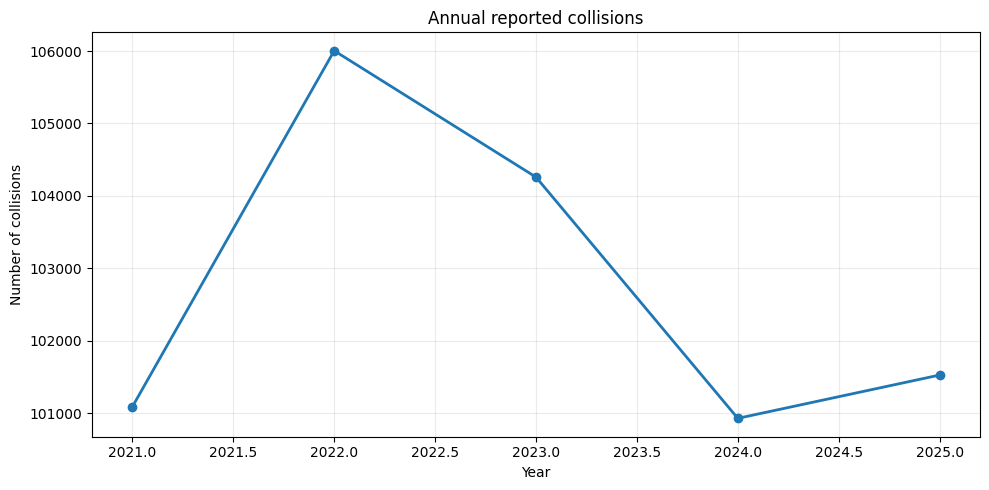

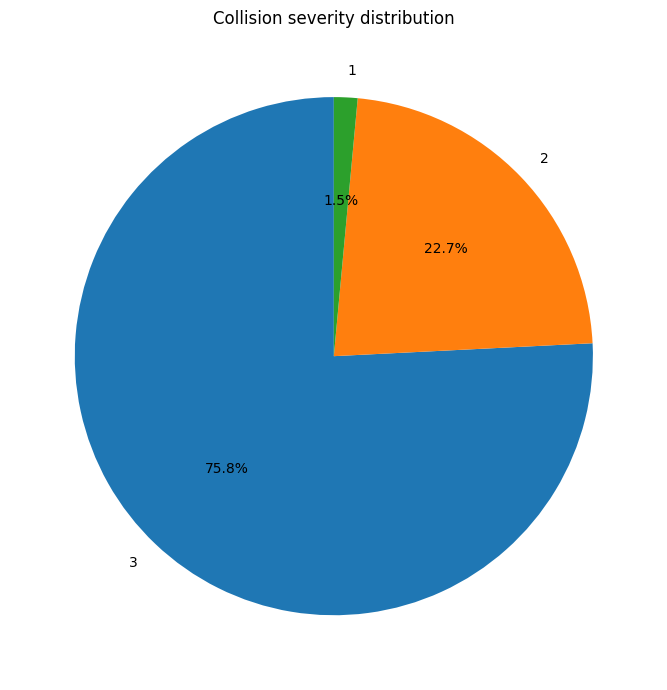

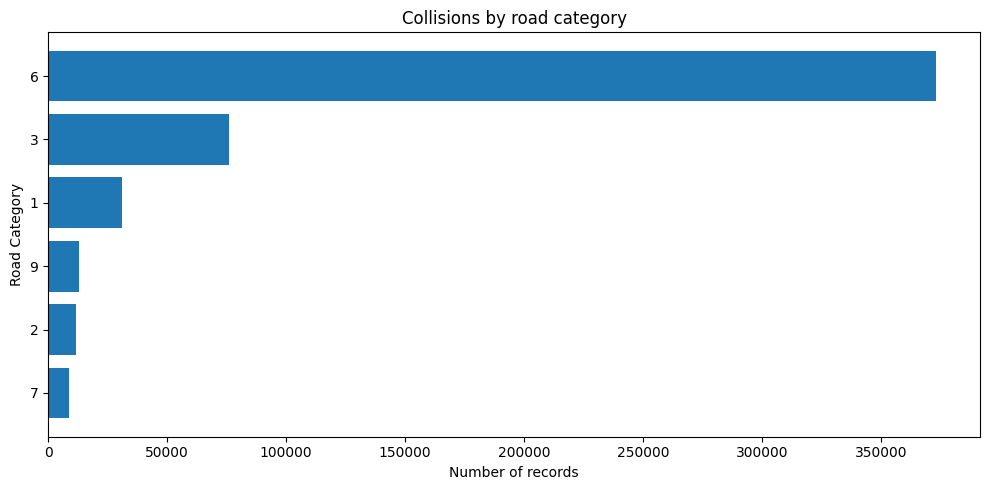

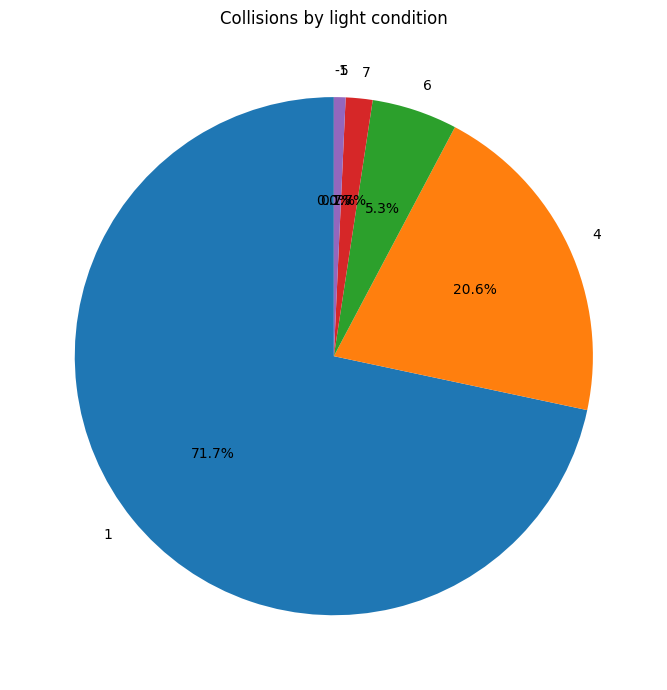

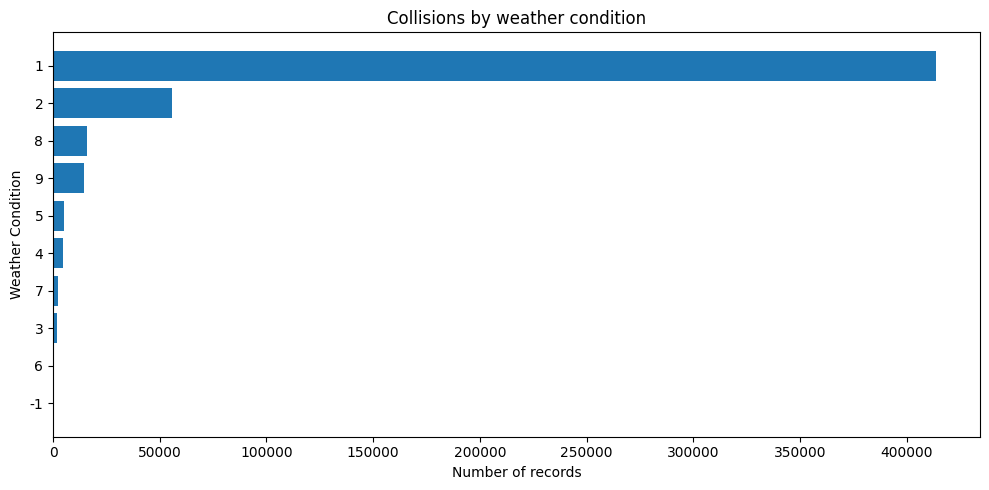

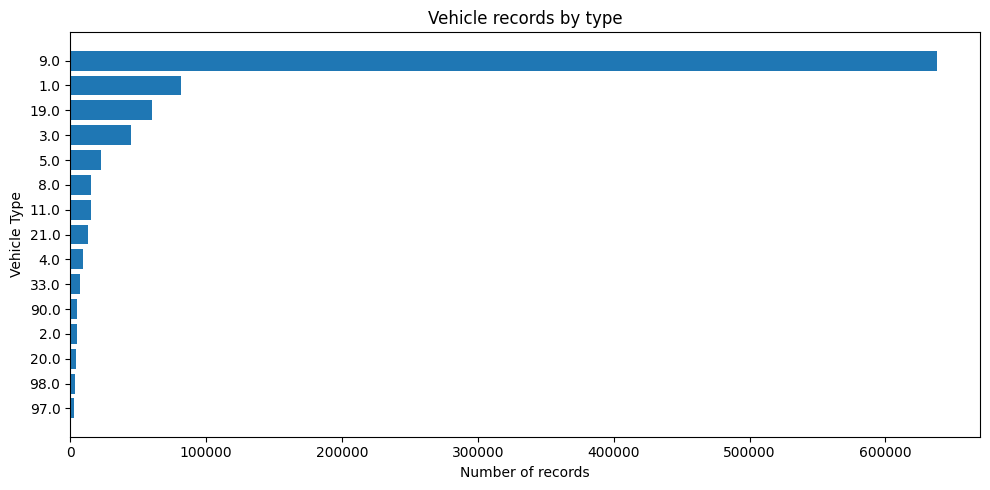

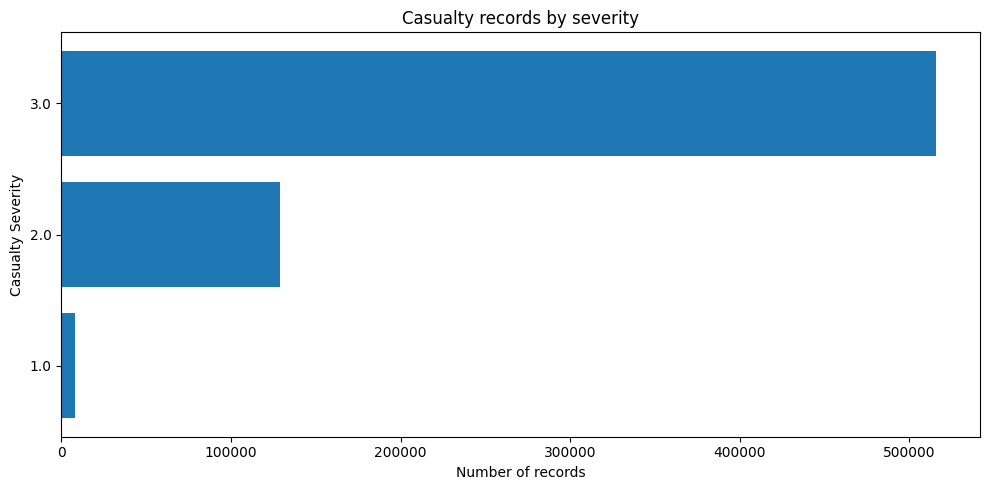

Charts saved:
- 01_annual_collisions_line.png
- 02_severity_pie.png
- 03_road_category_bar.png
- 04_light_conditions_pie.png
- 05_weather_conditions_bar.png
- 06_vehicle_type_bar.png
- 07_casualty_severity_bar.png


In [15]:
CHART_DIR = os.path.join(OUTPUT_DIR, "charts")
os.makedirs(CHART_DIR, exist_ok=True)

def to_small_pdf(sdf, limit=20):
    return sdf.limit(limit).toPandas()

def plot_bar(sdf, category, value, title, filename, horizontal=True, top_n=15):
    pdf = to_small_pdf(sdf.orderBy(F.col(value).desc()), top_n)
    if pdf.empty:
        print("No data for", title); return
    pdf[category] = pdf[category].astype(str)
    plt.figure(figsize=(10, 5))
    if horizontal:
        pdf = pdf.sort_values(value)
        plt.barh(pdf[category], pdf[value])
        plt.xlabel("Number of records")
        plt.ylabel(category.replace("_", " ").title())
    else:
        plt.bar(pdf[category], pdf[value])
        plt.xlabel(category.replace("_", " ").title())
        plt.ylabel("Number of records")
        plt.xticks(rotation=35, ha="right")
    plt.title(title); plt.tight_layout()
    plt.savefig(os.path.join(CHART_DIR, filename), dpi=160, bbox_inches="tight")
    plt.show(); plt.close()

def plot_pie(sdf, category, value, title, filename, top_n=6):
    pdf = to_small_pdf(sdf.orderBy(F.col(value).desc()), top_n + 1)
    if pdf.empty:
        print("No data for", title); return
    pdf[category] = pdf[category].astype(str)
    if len(pdf) > top_n:
        other = pdf.iloc[top_n:][value].sum()
        pdf = pdf.iloc[:top_n].copy()
        if other > 0:
            pdf = pd.concat([pdf, pd.DataFrame([{category:"Other", value:other}])], ignore_index=True)
    plt.figure(figsize=(7, 7))
    plt.pie(pdf[value], labels=pdf[category], autopct="%1.1f%%", startangle=90)
    plt.title(title); plt.tight_layout()
    plt.savefig(os.path.join(CHART_DIR, filename), dpi=160, bbox_inches="tight")
    plt.show(); plt.close()

def plot_line(sdf, x, y, title, filename):
    pdf = to_small_pdf(sdf.orderBy(F.col(x).asc()), 100)
    if pdf.empty:
        print("No data for", title); return
    pdf[x] = pd.to_numeric(pdf[x], errors="coerce")
    pdf[y] = pd.to_numeric(pdf[y], errors="coerce")
    pdf = pdf.dropna(subset=[x, y]).sort_values(x)
    plt.figure(figsize=(10, 5))
    plt.plot(pdf[x], pdf[y], marker="o", linewidth=2)
    plt.xlabel("Year"); plt.ylabel("Number of collisions")
    plt.title(title); plt.grid(True, alpha=0.25); plt.tight_layout()
    plt.savefig(os.path.join(CHART_DIR, filename), dpi=160, bbox_inches="tight")
    plt.show(); plt.close()

if "year_sql" in globals():
    plot_line(year_sql, "year", "collision_count", "Annual reported collisions", "01_annual_collisions_line.png")
if "severity_sql" in globals():
    plot_pie(severity_sql, "severity", "collision_count", "Collision severity distribution", "02_severity_pie.png")
if "road_sql" in globals():
    plot_bar(road_sql, "road_category", "collision_count", "Collisions by road category", "03_road_category_bar.png")
if "light_sql" in globals():
    plot_pie(light_sql, "light_condition", "collision_count", "Collisions by light condition", "04_light_conditions_pie.png")
if "weather_sql" in globals():
    plot_bar(weather_sql, "weather_condition", "collision_count", "Collisions by weather condition", "05_weather_conditions_bar.png")
if "vehicle_type_sql" in globals():
    plot_bar(vehicle_type_sql, "vehicle_type", "record_count", "Vehicle records by type", "06_vehicle_type_bar.png")
if "casualty_severity_sql" in globals():
    plot_bar(casualty_severity_sql, "casualty_severity", "record_count", "Casualty records by severity", "07_casualty_severity_bar.png")

print("Charts saved:")
for name in sorted(os.listdir(CHART_DIR)):
    if name.endswith(".png"): print("-", name)

In [18]:
import os

# Define output folders
OUTPUT_DIR = "/content/UK_Road_Safety_Spark_Outputs"

PARQUET_DIR = os.path.join(OUTPUT_DIR, "parquet")
CHART_DIR = os.path.join(OUTPUT_DIR, "charts")
SQL_DIR = os.path.join(OUTPUT_DIR, "sql_results")

# Create folders if they do not exist
os.makedirs(PARQUET_DIR, exist_ok=True)
os.makedirs(CHART_DIR, exist_ok=True)
os.makedirs(SQL_DIR, exist_ok=True)

print("All output directories are ready!")
print("Parquet:", PARQUET_DIR)
print("Charts:", CHART_DIR)
print("SQL Results:", SQL_DIR)

All output directories are ready!
Parquet: /content/UK_Road_Safety_Spark_Outputs/parquet
Charts: /content/UK_Road_Safety_Spark_Outputs/charts
SQL Results: /content/UK_Road_Safety_Spark_Outputs/sql_results


In [19]:
metrics = {
    "run_timestamp_utc": datetime.utcnow().isoformat() + "Z",
    "pyspark_version": pyspark.__version__,
    "execution_mode": "local[*] on Google Colab (single runtime, not a multi-node cluster)",
    "source_files": {
        "collisions": os.path.basename(COLLISIONS_PATH),
        "vehicles": os.path.basename(VEHICLES_PATH),
        "casualties": os.path.basename(CASUALTIES_PATH)
    },
    "three_distinct_source_files": len(set(source_paths)) == 3,
    "raw_rows": {
        "collisions": collisions_raw.count(),
        "vehicles": vehicles_raw.count(),
        "casualties": casualties_raw.count()
    },
    "clean_rows": {
        "collisions": collisions_clean.count(),
        "vehicles": vehicles_clean.count(),
        "casualties": casualties_clean.count()
    },
    "integrated_collision_rows": integrated.count(),
    "json_sample_rows_written": json_sample_rows,
    "json_sample_rows_read": json_round_trip_rows,
    "duplicate_collision_keys": duplicate_collision_keys,
    "unmatched_vehicle_rows": unmatched_vehicle_rows,
    "unmatched_casualty_rows": unmatched_casualty_rows,
    "integrated_row_count_preserved": integrated.count() == collision_base.count(),
    "elapsed_seconds": round(time.time() - start_time, 2)
}
with open(os.path.join(OUTPUT_DIR, "run_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
print(json.dumps(metrics, indent=2))
print("Charts:", CHART_DIR)
print("Parquet:", PARQUET_DIR)

if not metrics["three_distinct_source_files"] or not metrics["integrated_row_count_preserved"]:
    raise AssertionError("A final input/integration validation check failed.")

/tmp/ipykernel_477/3238942554.py:2: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "run_timestamp_utc": datetime.utcnow().isoformat() + "Z",


{
  "run_timestamp_utc": "2026-11-16T08:13:55.983446Z",
  "pyspark_version": "3.5.5",
  "execution_mode": "local[*] on Google Colab (single runtime, not a multi-node cluster)",
  "source_files": {
    "collisions": "dft-road-casualty-statistics-collision-last-5-years.csv",
    "vehicles": "dft-road-casualty-statistics-vehicle-last-5-years.csv",
    "casualties": "dft-road-casualty-statistics-casualty-last-5-years.csv"
  },
  "three_distinct_source_files": true,
  "raw_rows": {
    "collisions": 513801,
    "vehicles": 937265,
    "casualties": 652821
  },
  "clean_rows": {
    "collisions": 513801,
    "vehicles": 937265,
    "casualties": 652821
  },
  "integrated_collision_rows": 513801,
  "json_sample_rows_written": 5000,
  "json_sample_rows_read": 5000,
  "duplicate_collision_keys": 0,
  "unmatched_vehicle_rows": 0,
  "unmatched_casualty_rows": 0,
  "integrated_row_count_preserved": true,
  "elapsed_seconds": 2510.09
}
Charts: /content/UK_Road_Safety_Spark_Outputs/charts
Parquet: /

In [20]:
zip_path = shutil.make_archive("/content/UK_Road_Safety_Spark_Outputs", "zip", OUTPUT_DIR)
print("Created:", zip_path)
from google.colab import files
files.download(zip_path)

Created: /content/UK_Road_Safety_Spark_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
spark.stop()
print("Spark session stopped.")

Spark session stopped.
